**Regression** (Linear regression ,KNN Models)

Import Libraries

In [51]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

:

In [52]:
def compute_metrics(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2


def evaluate_on_test(name, y_true, y_pred, color='blue'):

    mae, rmse, r2 = compute_metrics(y_true, y_pred)
    print(f'\n{name}:')
    print(f'  - MAE: {mae:.4f}')
    print(f'  - RMSE: {rmse:.4f}')
    print(f'  - R2 Score: {r2:.4f}')

    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, alpha=0.7, color=color)
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()],
             'r--', lw=2)
    plt.xlabel('Actual Values (xg)')
    plt.ylabel('Predicted Values (xg)')
    plt.title(f'{name}: Predicted vs Actual')
    plt.grid(True)
    plt.show()
    print('\n-----------------------------------')
    return {'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2}


def plot_k_curve(k_values, scores, title):
    plt.figure(figsize=(8, 4))
    plt.plot(k_values, scores, marker='o', color='teal', linestyle='-')
    plt.title(title)
    plt.xlabel('Value of k')
    plt.ylabel('Validation R2 Score')
    plt.grid(True)
    plt.show()


read data and EDA

In [53]:
df = pd.read_csv('matches.csv')
print('sample:')
print(df.head())
print('\n data info:')
df.info()
print('\n data description:')
print (df.describe())


print(f"\n Missing values in target (xg) before cleaning: {df['xg'].isna().sum()}")
print(f'Dataset shape before cleaning: {df.shape}')
df = df.dropna(subset=['xg'])
print(f'Dataset shape after dropping NaN in xg: {df.shape}') # الداتا بعد الclaening فيها كام صف وكام عمود


sample:
   Unnamed: 0        date   time            comp        round  day venue  \
0           1  2021-08-15  16:30  Premier League  Matchweek 1  Sun  Away   
1           2  2021-08-21  15:00  Premier League  Matchweek 2  Sat  Home   
2           3  2021-08-28  12:30  Premier League  Matchweek 3  Sat  Home   
3           4  2021-09-11  15:00  Premier League  Matchweek 4  Sat  Away   
4           6  2021-09-18  15:00  Premier League  Matchweek 5  Sat  Home   

  result   gf   ga  ...  match report  notes    sh   sot  dist   fk   pk  \
0      L  0.0  1.0  ...  Match Report    NaN  18.0   4.0  16.9  1.0  0.0   
1      W  5.0  0.0  ...  Match Report    NaN  16.0   4.0  17.3  1.0  0.0   
2      W  5.0  0.0  ...  Match Report    NaN  25.0  10.0  14.3  0.0  0.0   
3      W  1.0  0.0  ...  Match Report    NaN  25.0   8.0  14.0  0.0  0.0   
4      D  0.0  0.0  ...  Match Report    NaN  16.0   1.0  15.7  1.0  0.0   

  pkatt season             team  
0   0.0   2022  Manchester City  
1   0.0   

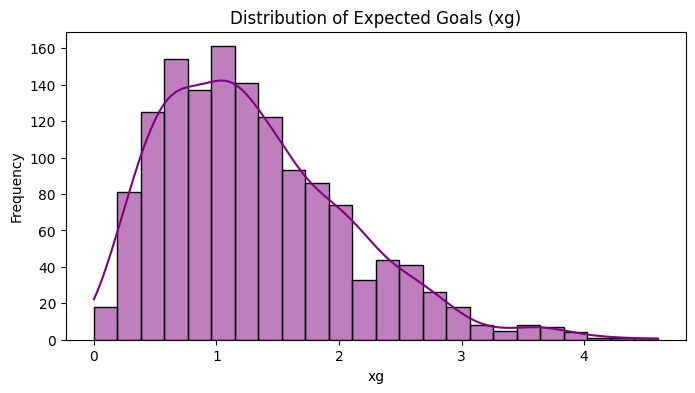

In [54]:
plt.figure(figsize=(8, 4))
sns.histplot(df['xg'], kde=True, color='purple')
plt.title('Distribution of Expected Goals (xg)')
plt.xlabel('xg')
plt.ylabel('Frequency')
plt.show()


In [55]:
numerical_cols = ['sh', 'dist', 'pkatt']
categorical_cols = ['venue', 'day', 'formation']
X = df[numerical_cols + categorical_cols]
y = df['xg']

numerical_cols = X.select_dtypes(include='number').columns.tolist()
categorical_cols = X.select_dtypes(exclude='number').columns.tolist()
print(f'\n Numerical columns: {numerical_cols}')
print(f'Categorical columns: {categorical_cols}')



 Numerical columns: ['sh', 'dist', 'pkatt']
Categorical columns: ['venue', 'day', 'formation']


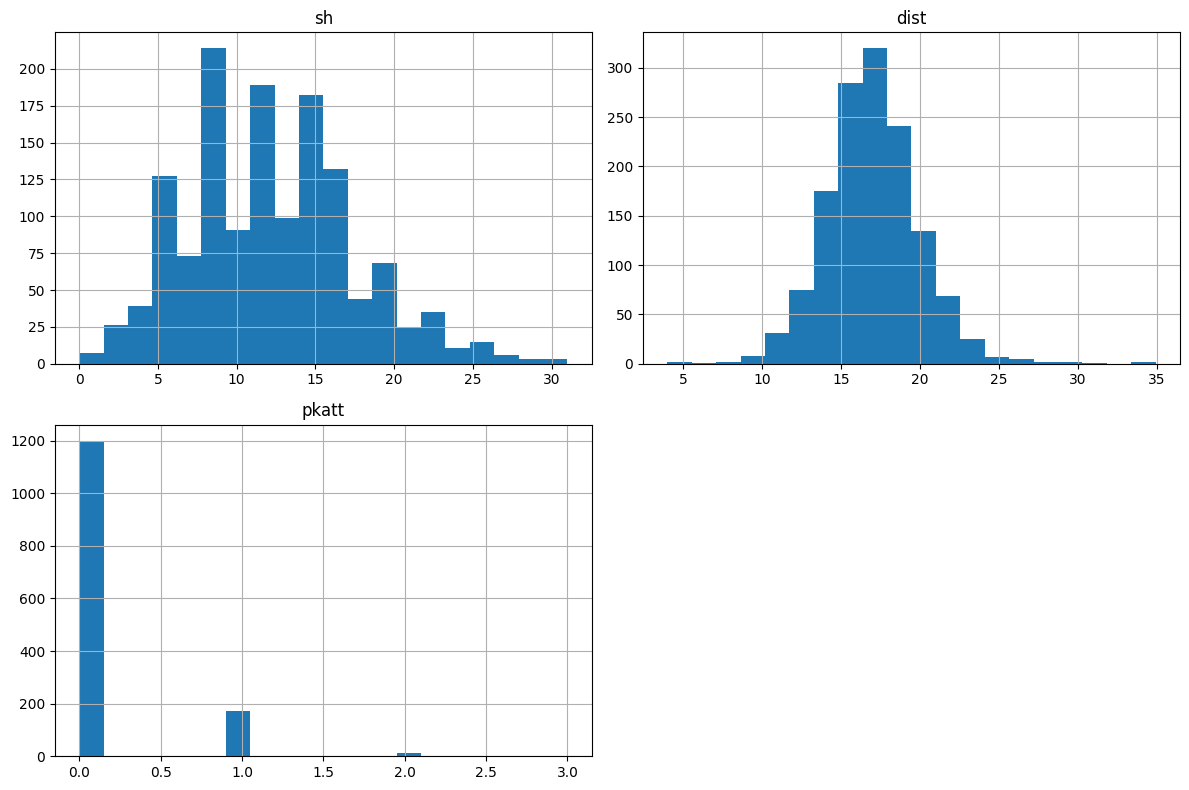

In [56]:

df[numerical_cols].hist(bins=20, figsize=(12, 8))
plt.tight_layout()
plt.show()



 the heatmap:


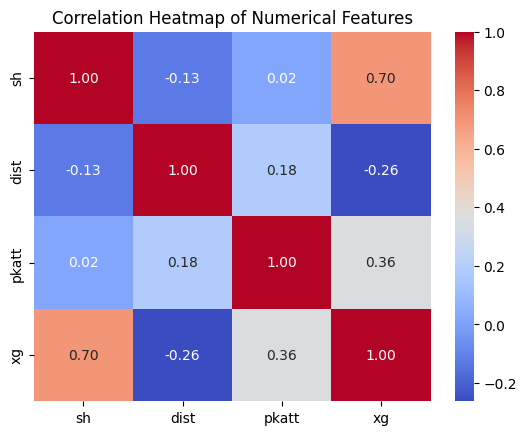

In [57]:
print('\n the heatmap:')
sns.heatmap(df[numerical_cols + ['xg']].corr(), annot=True, cmap='coolwarm',
            fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

In [58]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1764, random_state=42)

print(f'Training set size: {X_train.shape[0]}')
print(f'Validation set size: {X_val.shape[0]}')
print(f'Test set size: {X_test.shape[0]}')

Training set size: 971
Validation set size: 209
Test set size: 209


In [59]:

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, numerical_cols),
    ('cat', cat_transformer, categorical_cols),
])


lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression()),
])
lr_pipeline.fit(X_train, y_train)

mae, rmse, r2 = compute_metrics(y_val, lr_pipeline.predict(X_val))
print('\nLinear Regression on Validation :')
print(f'MAE: {mae:.4f}')
print(f'RMSE: {rmse:.4f}')
print(f'R2 Score: {r2:.4f}')


Linear Regression on Validation :
MAE: 0.3401
RMSE: 0.4605
R2 Score: 0.6304



 The best k is: 15


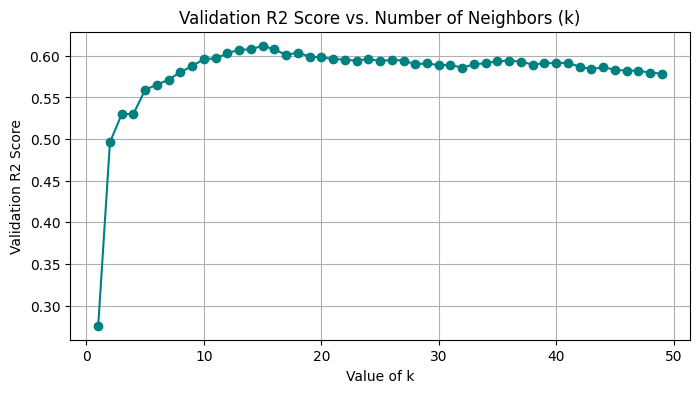

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['sh', 'dist', 'pkatt']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['venue', 'day',
                                                   'formation'])])),
                ('model', KNeighborsRegressor(n_neighbors=15))])

In [60]:

k_values = list(range(1, 50))
best_k = None
best_val_r2 = -float('inf')
val_r2_scores = []

for k in k_values:
    knn_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', KNeighborsRegressor(n_neighbors=k)),
    ])
    knn_pipeline.fit(X_train, y_train)
    val_r2 = r2_score(y_val, knn_pipeline.predict(X_val))
    val_r2_scores.append(val_r2)

    if val_r2 > best_val_r2:
        best_val_r2 = val_r2
        best_k = k

print(f'\n The best k is: {best_k}')
plot_k_curve(k_values, val_r2_scores,
             'Validation R2 Score vs. Number of Neighbors (k)')

best_knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', KNeighborsRegressor(n_neighbors=best_k)),
])
best_knn_pipeline.fit(X_train, y_train)

In [61]:

print('\nFinal number of features after preprocessing:',
      len(preprocessor.get_feature_names_out()))


Final number of features after preprocessing: 28



Linear Regression (Sklearn built in ):
  - MAE: 0.3111
  - RMSE: 0.3950
  - R2 Score: 0.7021


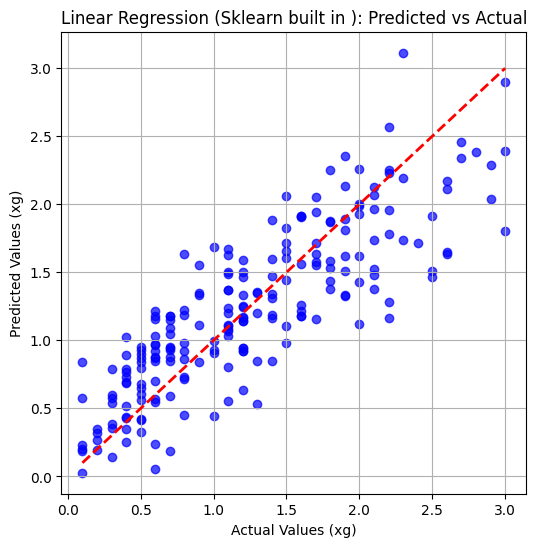


-----------------------------------

KNN Regressor (Sklearn built in ):
  - MAE: 0.3324
  - RMSE: 0.4177
  - R2 Score: 0.6669


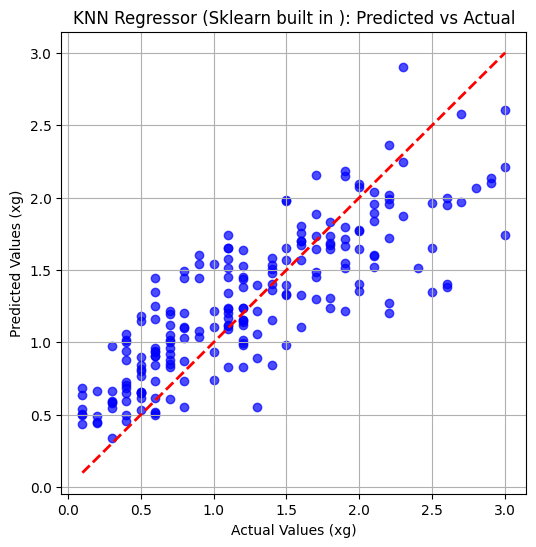


-----------------------------------


In [62]:
results = []
for name, model in [('Linear Regression (Sklearn built in )', lr_pipeline),
                    ('KNN Regressor (Sklearn built in )', best_knn_pipeline)]:
    results.append(evaluate_on_test(name, y_test, model.predict(X_test)))


In [63]:
scratch_preprocessor = clone(preprocessor)
X_train_proc = scratch_preprocessor.fit_transform(X_train)
X_val_proc = scratch_preprocessor.transform(X_val)
X_test_proc = scratch_preprocessor.transform(X_test)

y_train_np = y_train.to_numpy()
y_val_np = y_val.to_numpy()
y_test_np = y_test.to_numpy()

In [64]:

class LinearRegressionScratch:

    def __init__(self, lr=0.05, epochs=3000):
        self.lr = lr
        self.epochs = epochs
        self.weights = None
        self.bias = 0.0

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for _ in range(self.epochs):
            y_pred = np.dot(X, self.weights) + self.bias
            error = y_pred - y

            dw = (2 / n_samples) * np.dot(X.T, error)
            db = (2 / n_samples) * np.sum(error)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        return np.dot(X, self.weights) + self.bias





In [65]:
class KNeighborsRegressorScratch:

    def __init__(self, n_neighbors=5):
        self.k = n_neighbors
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def predict(self, X):
        predictions = []
        for x in X:

            distances = np.sqrt(np.sum((self.X_train - x) ** 2, axis=1))

            k_indices = np.argsort(distances)[: self.k]

            k_nearest_values = self.y_train[k_indices]
            predictions.append(np.mean(k_nearest_values))
        return np.array(predictions)

In [66]:
lr_scratch = LinearRegressionScratch(lr=0.05, epochs=3000)
lr_scratch.fit(X_train_proc, y_train_np)



 The best k is: 15


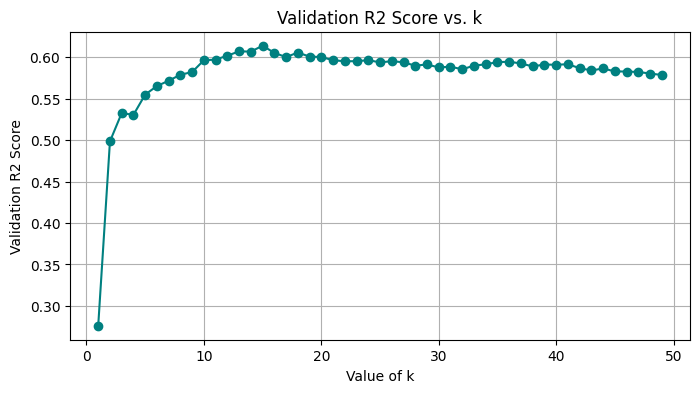

In [67]:

best_k_scratch = None
best_val_r2_scratch = -float('inf')
val_r2_scores_scratch = []

for k in k_values:
    knn_temp = KNeighborsRegressorScratch(n_neighbors=k)
    knn_temp.fit(X_train_proc, y_train_np)
    score = r2_score(y_val_np, knn_temp.predict(X_val_proc))
    val_r2_scores_scratch.append(score)

    if score > best_val_r2_scratch:
        best_val_r2_scratch = score
        best_k_scratch = k

print(f'\n The best k is: {best_k_scratch}')
plot_k_curve(k_values, val_r2_scores_scratch,
             'Validation R2 Score vs. k')

best_knn_scratch = KNeighborsRegressorScratch(n_neighbors=best_k_scratch)
best_knn_scratch.fit(X_train_proc, y_train_np)


Linear Regression (From Scratch):
  - MAE: 0.3109
  - RMSE: 0.3950
  - R2 Score: 0.7021


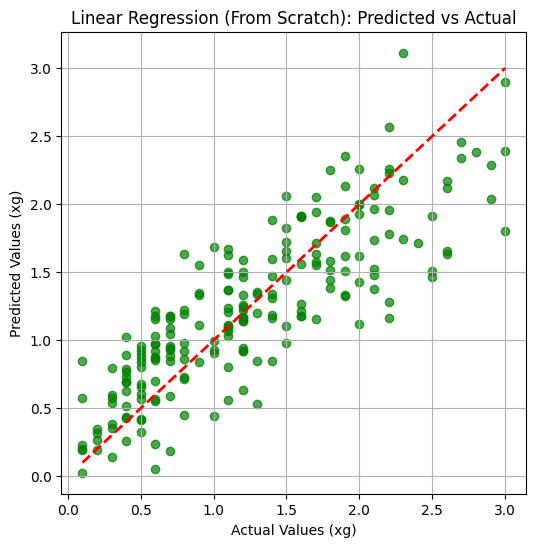


-----------------------------------

KNN Regressor (From Scratch):
  - MAE: 0.3321
  - RMSE: 0.4173
  - R2 Score: 0.6675


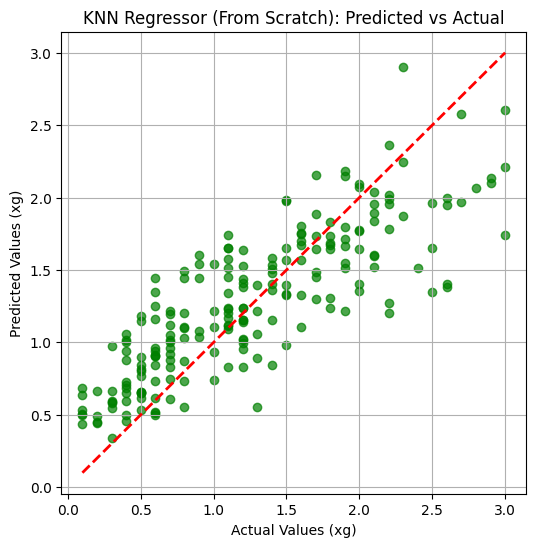


-----------------------------------


In [68]:

for name, model in [('Linear Regression (From Scratch)', lr_scratch),
                    ('KNN Regressor (From Scratch)', best_knn_scratch)]:
    results.append(
        evaluate_on_test(name, y_test_np, model.predict(X_test_proc), color='green'))


In [69]:
summary = pd.DataFrame(results).set_index('Model').round(4)

print('   TEST SET SUMMARY (all models)             ')

print(summary)
print('\n-----------------------------')
print('Best by R2  :', summary['R2'].idxmax())
print('Best by MAE :', summary['MAE'].idxmin())
print('Best by RMSE:', summary['RMSE'].idxmin())

joblib.dump(lr_pipeline, 'lr_model.joblib')
joblib.dump(best_knn_pipeline, 'knn_model.joblib')


   TEST SET SUMMARY (all models)             
                                          MAE    RMSE      R2
Model                                                        
Linear Regression (Sklearn built in )  0.3111  0.3950  0.7021
KNN Regressor (Sklearn built in )      0.3324  0.4177  0.6669
Linear Regression (From Scratch)       0.3109  0.3950  0.7021
KNN Regressor (From Scratch)           0.3321  0.4173  0.6675

-----------------------------
Best by R2  : Linear Regression (Sklearn built in )
Best by MAE : Linear Regression (From Scratch)
Best by RMSE: Linear Regression (Sklearn built in )


['knn_model.joblib']